   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 697.4/697.4 kB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 527.0/527.0 kB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 16.5 MB/s eta 0:00:00
Enter your Hugging Face token: ··········


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

...

Epoch,Training Loss,Validation Loss
1,0.319889,0.253190
2,0.235509,0.290547
3,0.206569,0.246085


Saved LoRA adapter to: /content/drive/MyDrive/google/gemma-3-1b-it_newsft


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Fine-tuned model reloaded.
  conversation_id  turn_index  \
0          100485           0   
1          100485           3   
2          100485           5   
3          100796           0   
4          100796           2   

                                        history_text  \
0                                                      
1  USER: I want a model airplane\nSYSTEM: Okay, t...   
2  USER: I want a model airplane\nSYSTEM: Okay, t...   
3                                                      
4                              USER: hi!\nSYSTEM: hi   

          current_turn_text    intent predicted_label raw_response  
0   I want a model airplane    Reveal          Reveal       Reveal  
1  I want something bigger.    Reveal       Interpret    Interpret  
2                        ok    Reveal       Interpret    Interpret  
3                       hi!  Chitchat          Reveal       Reveal  
4       I wanna a bicycle!!    Reveal          Reveal       Reveal  
Rows with valid predict

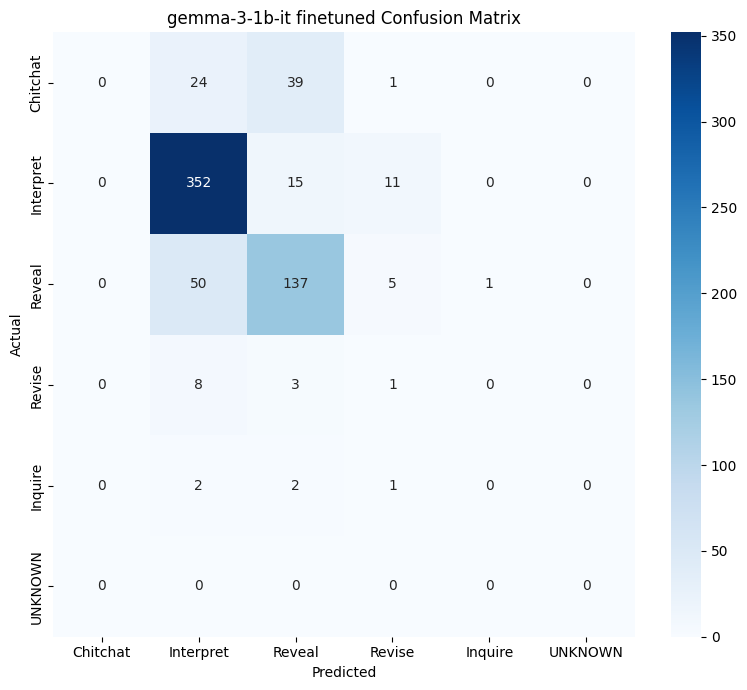

Saved predictions to: /content/drive/MyDrive/google/gemma-3-1b-it_finetuned_test_predictions_newsft.csv
                  model                                            setup  \
0  google/gemma-3-1b-it  Response-only FT + PEFT/LoRA + template variant   

   accuracy  macro_f1  weighted_f1  chitchat_f1  interpret_f1  reveal_f1  \
0  0.751534  0.272292     0.711099          0.0      0.864865    0.70437   

   revise_f1  inquire_f1  unknown_f1  unknown_count  
0   0.064516         0.0         0.0              0  


In [1]:
# -*- coding: utf-8 -*-

!pip install -q transformers datasets accelerate peft trl bitsandbytes scikit-learn pandas matplotlib seaborn sentencepiece

import os
import re
import gc
import json
import torch
import numpy as np
import pandas as pd
from getpass import getpass

from datasets import Dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

from huggingface_hub import login, whoami
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    BitsAndBytesConfig,
    Trainer,
    DataCollatorForSeq2Seq,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel

# =========================
# 1. AUTH + DRIVE
# =========================
HF_TOKEN = getpass("Enter your Hugging Face token: ").strip()
login(HF_TOKEN)
print("HF user:", whoami())

from google.colab import drive
drive.mount('/content/drive')

# =========================
# 2. CONFIG
# =========================
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"
MODEL_NAME = "google/gemma-3-1b-it"
OUTPUT_DIR = "/content/drive/MyDrive/google/gemma-3-1b-it_newsft"
PRED_PATH = "/content/drive/MyDrive/google/gemma-3-1b-it_finetuned_test_predictions_newsft.csv"

RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20

VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise", "Inquire"]
MAX_SEQ_LEN = 512

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Model:", MODEL_NAME)
print("Saving to:", OUTPUT_DIR)

# =========================
# 3. LOAD DATA
# =========================
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = (
    pd.DataFrame(all_rows)
    .sort_values(["conversation_id", "turn_index"])
    .reset_index(drop=True)
)

df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

print("Full rows:", len(df_turns_full))
print("Target rows:", len(target_df))
print("Unique conversations:", df_turns_full["conversation_id"].nunique())

# =========================
# 4. SPLIT DATA
# =========================
gss1 = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Train rows:", len(train_df))
print("Val rows  :", len(val_df))
print("Test rows :", len(test_df))
print("Overlap train-test:", len(set(train_df["conversation_id"]) & set(test_df["conversation_id"])))
print("Overlap train-val :", len(set(train_df["conversation_id"]) & set(val_df["conversation_id"])))

# =========================
# 5. BUILD CONTEXT
# =========================
def build_history_and_current_turn(full_conv: pd.DataFrame, current_turn_index: int):
    history_df = full_conv[full_conv["turn_index"] < current_turn_index].copy()
    current_df = full_conv[
        (full_conv["turn_index"] == current_turn_index) &
        (full_conv["role"] == "user")
    ].copy()

    history_lines = []
    for _, row in history_df.iterrows():
        role = str(row["role"]).upper().strip()
        text = str(row["text"]).strip()
        if text:
            history_lines.append(f"{role}: {text}")

    history_text = "\n".join(history_lines)
    current_turn_text = str(current_df.iloc[0]["text"]).strip() if len(current_df) > 0 else ""
    return history_text, current_turn_text


def build_prompt(history_text: str, current_turn_text: str) -> str:
    return f"""### Task:
You are an e-commerce conversational AI intent classifier.

Predict the intent of the current user utterance using the available dialogue context.

### Intent Labels:
- Chitchat: casual or social talk not directly contributing new shopping constraints
- Reveal: the user starts or reveals a shopping need or request
- Interpret: the user provides information, answers a question, or adds preferences/details
- Revise: the user modifies, corrects, or refines a previous request or suggestion
- Inquire: the user asks for additional information, clarification, or details

### Dialogue Context:
{history_text if history_text.strip() else "NONE"}

### Current User Utterance:
{current_turn_text}

### Instruction:
Return exactly one label from:
Chitchat, Reveal, Interpret, Revise, Inquire

### Answer:"""


def build_completion(label: str) -> str:
    return f" {label}"


def build_inference_prompt(history_text: str, current_turn_text: str) -> str:
    return f"""### Task:
You are an e-commerce conversational AI intent classifier.

Predict the intent of the current user utterance using the available dialogue context.

### Intent Labels:
- Chitchat: casual or social talk not directly contributing new shopping constraints
- Reveal: the user starts or reveals a shopping need or request
- Interpret: the user provides information, answers a question, or adds preferences/details
- Revise: the user modifies, corrects, or refines a previous request or suggestion
- Inquire: the user asks for additional information, clarification, or details

### Dialogue Context:
{history_text if history_text.strip() else "NONE"}

### Current User Utterance:
{current_turn_text}

### Instruction:
Return exactly one label from:
Chitchat, Reveal, Interpret, Revise, Inquire

### Answer:"""


def build_sft_dataframe(df_split: pd.DataFrame, turns_by_conv: dict):
    rows = []

    for _, row in df_split.iterrows():
        conv_df = turns_by_conv[row["conversation_id"]]
        history_text, current_turn_text = build_history_and_current_turn(
            conv_df, row["turn_index"]
        )

        prompt = build_prompt(history_text, current_turn_text)
        completion = build_completion(row["intent"])

        rows.append({
            "conversation_id": row["conversation_id"],
            "turn_index": row["turn_index"],
            "history_text": history_text,
            "current_turn_text": current_turn_text,
            "intent": row["intent"],
            "prompt": prompt,
            "completion": completion,
            "text": prompt + completion
        })

    return pd.DataFrame(rows)


train_sft_df = build_sft_dataframe(train_df, turns_by_conv_full)
val_sft_df   = build_sft_dataframe(val_df, turns_by_conv_full)
test_sft_df  = build_sft_dataframe(test_df, turns_by_conv_full)

train_ds = Dataset.from_pandas(
    train_sft_df[["prompt", "completion"]],
    preserve_index=False
)
val_ds = Dataset.from_pandas(
    val_sft_df[["prompt", "completion"]],
    preserve_index=False
)

print(train_sft_df[["prompt", "completion", "intent"]].head(2))
print(train_ds)
print(val_ds)

# =========================
# 6. TOKENIZER + MODEL
# =========================
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.float16,
    trust_remote_code=True
)

base_model.config.use_cache = False
base_model = prepare_model_for_kbit_training(base_model)

print("Base model loaded.")

# =========================
# 7. RESPONSE-ONLY TOKENIZATION
# =========================
def tokenize_response_only(example):
    prompt_ids = tokenizer(
        example["prompt"],
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    completion_ids = tokenizer(
        example["completion"],
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    if tokenizer.eos_token_id is not None:
        completion_ids = completion_ids + [tokenizer.eos_token_id]

    input_ids = prompt_ids + completion_ids
    labels = [-100] * len(prompt_ids) + completion_ids
    attention_mask = [1] * len(input_ids)

    if len(input_ids) > MAX_SEQ_LEN:
        overflow = len(input_ids) - MAX_SEQ_LEN
        input_ids = input_ids[overflow:]
        attention_mask = attention_mask[overflow:]
        labels = labels[overflow:]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }

train_tokenized = train_ds.map(
    tokenize_response_only,
    remove_columns=train_ds.column_names
)

val_tokenized = val_ds.map(
    tokenize_response_only,
    remove_columns=val_ds.column_names
)

print(train_tokenized)
print(val_tokenized)

# =========================
# 8. LORA
# =========================
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"]
)

model = get_peft_model(base_model, lora_config)
model.gradient_checkpointing_enable()

for name, param in model.named_parameters():
    if param.requires_grad:
        param.data = param.data.to(torch.float32)

model.print_trainable_parameters()

trainable_dtypes = {}
for name, param in model.named_parameters():
    if param.requires_grad:
        trainable_dtypes[str(param.dtype)] = trainable_dtypes.get(str(param.dtype), 0) + 1
print("Trainable param dtypes:", trainable_dtypes)

# =========================
# 9. TRAINING ARGS
# =========================
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=1e-4,
    num_train_epochs=3,
    logging_steps=20,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    report_to="none",
    fp16=False,
    bf16=False,
    warmup_steps=50,
    lr_scheduler_type="cosine",
    max_grad_norm=0.0,
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    return_tensors="pt"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    data_collator=data_collator,
)

print("Trainer ready.")
print("GPU:", torch.cuda.get_device_name(0))
print("bnb compute dtype:", bnb_config.bnb_4bit_compute_dtype)
print("model dtype:", next(model.parameters()).dtype)
print("fp16:", training_args.fp16)
print("bf16:", training_args.bf16)

# =========================
# 10. TRAIN
# =========================
trainer.train()

trainer.model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("Saved LoRA adapter to:", OUTPUT_DIR)

# =========================
# 11. INFERENCE HELPERS
# =========================
def normalize_label(text: str) -> str:
    text = (text or "").strip()
    if not text:
        return "UNKNOWN"

    text = text.split("\n")[0].strip()
    text = re.sub(r"^[\"'`]+|[\"'`]+$", "", text)
    text = re.sub(r"[.,:;!?]+$", "", text).strip()

    label_map = {label.lower(): label for label in VALID_LABELS}
    lowered = text.lower()

    if lowered in label_map:
        return label_map[lowered]

    patterns = [
        r"\b(chitchat|reveal|interpret|revise|inquire)\b",
        r"label\s*[:\-]?\s*(chitchat|reveal|interpret|revise|inquire)\b",
        r"intent\s*[:\-]?\s*(chitchat|reveal|interpret|revise|inquire)\b",
        r"the answer is\s*(chitchat|reveal|interpret|revise|inquire)\b",
        r"the intent is\s*(chitchat|reveal|interpret|revise|inquire)\b",
        r"answer\s*[:\-]?\s*(chitchat|reveal|interpret|revise|inquire)\b",
    ]

    for pattern in patterns:
        match = re.search(pattern, lowered, flags=re.IGNORECASE)
        if match:
            return label_map[match.group(1).lower()]

    return "UNKNOWN"

# =========================
# 12. RELOAD FOR EVAL
# =========================
del trainer
gc.collect()
torch.cuda.empty_cache()

tokenizer = AutoTokenizer.from_pretrained(OUTPUT_DIR, trust_remote_code=True)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

base_eval_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.float16,
    trust_remote_code=True
)

ft_model = PeftModel.from_pretrained(base_eval_model, OUTPUT_DIR)
ft_model.eval()

print("Fine-tuned model reloaded.")

def predict_label_ft(model, tokenizer, history_text: str, current_turn_text: str):
    prompt = build_inference_prompt(history_text, current_turn_text)

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_SEQ_LEN
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=3,
            do_sample=False,
            temperature=0.0,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    input_len = inputs["input_ids"].shape[1]
    new_tokens = outputs[0][input_len:]
    raw_output = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

    pred = normalize_label(raw_output)
    return pred, raw_output

# =========================
# 13. PREDICT
# =========================
results = []

for _, row in test_sft_df.iterrows():
    pred_label, raw_output = predict_label_ft(
        ft_model,
        tokenizer,
        row["history_text"],
        row["current_turn_text"]
    )

    results.append({
        "conversation_id": row["conversation_id"],
        "turn_index": row["turn_index"],
        "history_text": row["history_text"],
        "current_turn_text": row["current_turn_text"],
        "intent": row["intent"],
        "predicted_label": pred_label,
        "raw_response": raw_output
    })

pred_df = pd.DataFrame(results)
print(pred_df.head())

# =========================
# 14. EVAL
# =========================
unknown_count = (~pred_df["predicted_label"].isin(VALID_LABELS)).sum()
print("Rows with valid predictions:", pred_df["predicted_label"].isin(VALID_LABELS).sum())
print("Rows with UNKNOWN/ERROR predictions:", unknown_count)

eval_df = pred_df.copy()
eval_df["predicted_label_eval"] = eval_df["predicted_label"].where(
    eval_df["predicted_label"].isin(VALID_LABELS),
    "UNKNOWN"
)

labels_for_report = VALID_LABELS + ["UNKNOWN"]

y_true = eval_df["intent"]
y_pred = eval_df["predicted_label_eval"]

report_text = classification_report(
    y_true, y_pred,
    labels=labels_for_report,
    digits=3,
    zero_division=0
)

report_dict = classification_report(
    y_true, y_pred,
    labels=labels_for_report,
    digits=3,
    zero_division=0,
    output_dict=True
)

print(report_text)

cm = confusion_matrix(y_true, y_pred, labels=labels_for_report)
cm_df = pd.DataFrame(
    cm,
    index=[f"true_{x}" for x in labels_for_report],
    columns=[f"pred_{x}" for x in labels_for_report]
)

print(cm_df)

plt.figure(figsize=(8, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels_for_report,
    yticklabels=labels_for_report,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("gemma-3-1b-it finetuned Confusion Matrix")
plt.tight_layout()
plt.show()

# =========================
# 15. SAVE PREDICTIONS
# =========================
pred_df.to_csv(PRED_PATH, index=False)
print("Saved predictions to:", PRED_PATH)

summary_row = {
    "model": MODEL_NAME,
    "setup": "Response-only FT + PEFT/LoRA + template variant",
    "accuracy": report_dict["accuracy"],
    "macro_f1": report_dict["macro avg"]["f1-score"],
    "weighted_f1": report_dict["weighted avg"]["f1-score"],
    "chitchat_f1": report_dict.get("Chitchat", {}).get("f1-score", 0.0),
    "interpret_f1": report_dict.get("Interpret", {}).get("f1-score", 0.0),
    "reveal_f1": report_dict.get("Reveal", {}).get("f1-score", 0.0),
    "revise_f1": report_dict.get("Revise", {}).get("f1-score", 0.0),
    "inquire_f1": report_dict.get("Inquire", {}).get("f1-score", 0.0),
    "unknown_f1": report_dict.get("UNKNOWN", {}).get("f1-score", 0.0),
    "unknown_count": int(unknown_count),
}

summary_df = pd.DataFrame([summary_row])
print(summary_df)

In [2]:
import time
import pandas as pd

results = []
inference_times = []

for _, row in test_sft_df.iterrows():
    start = time.time()

    pred_label, raw_output = predict_label_ft(
        ft_model,
        tokenizer,
        row["history_text"],
        row["current_turn_text"]
    )

    elapsed = time.time() - start
    inference_times.append(elapsed)

    results.append({
        "conversation_id": row["conversation_id"],
        "turn_index": row["turn_index"],
        "history_text": row["history_text"],
        "current_turn_text": row["current_turn_text"],
        "intent": row["intent"],
        "predicted_label": pred_label,
        "raw_response": raw_output,
        "inference_time_sec": elapsed,
    })

pred_df = pd.DataFrame(results)

print("Average inference time per sample (sec):", pred_df["inference_time_sec"].mean())
print("Median inference time per sample (sec):", pred_df["inference_time_sec"].median())
print("Min inference time per sample (sec):", pred_df["inference_time_sec"].min())
print("Max inference time per sample (sec):", pred_df["inference_time_sec"].max())
print("Total inference time (sec):", pred_df["inference_time_sec"].sum())

Average inference time per sample (sec): 0.338293935623637
Median inference time per sample (sec): 0.2707993984222412
Min inference time per sample (sec): 0.24657440185546875
Max inference time per sample (sec): 1.6480095386505127
Total inference time (sec): 220.56764602661133
